# 研究室見学向け：画像を使った異常検知の研究概要図

2026年10月23日。見学者へ、正常画像だけで学ぶ再構成型の異常検知を説明するための図です。

- **図①**：学習と検査の流れ、研究課題と今後の方向を16:9で表示。
- **図②**：正常／破損の実画像と、同じ学習済みモデルによる復元・誤差マップ。
- 上から実行すると、出力付きの図と `docs/figures/lab_visit_20261023/` のPNG・SVGを作ります。同名の図は再実行時に更新します。
- 写真・復元画像・マップは実データです。学習の流れを描く矢印や箱は説明用の図式で、再学習はしません。性能比較や閾値による判定も行いません。

画像名・見出し・配色は次の設定セルで変更できます。モデルは既存bottle比較実験のA_original（Hybrid VAE）を平均推論で使用します。Sparse VAEの出力ではありません。


In [1]:
from pathlib import Path
from io import BytesIO
import hashlib
import json
import numpy as np
import torch
from torch import nn
from torchvision import transforms
from PIL import Image
from skimage.metrics import structural_similarity as ssim
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Circle, PathPatch
from matplotlib.path import Path as PlotPath
from IPython.display import display, Markdown

%matplotlib inline

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'code/202610/261022画像反復と回転拡張モデルのAUROC比較.ipynb').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('このリポジトリ内を作業ディレクトリにしてください。')

TRAIN_EXAMPLE_NAMES = ('000.png', '001.png', '002.png')
NORMAL_EXAMPLE = 'good/000.png'
ABNORMAL_EXAMPLE = 'broken_large/000.png'
MODEL_PATH = ROOT / 'saved_models/rotation_control_20261021/20261021_232232_a54302ed/seed_42/A_original/model_final.pth'
EXPORT_DIR = ROOT / 'docs/figures/lab_visit_20261023'
TITLE = '画像から、製品の「いつもと違う」を見つける'
SUBTITLE = '正常の見た目をAIに学ばせ、検査画像との違いを探す研究'
COLORS = {'ink': '#183345', 'muted': '#526778', 'accent': '#197d82',
          'learning': '#ecf5ef', 'inspection': '#edf3f8', 'line': '#cbd9df',
          'challenge': '#fff2df', 'future': '#e6f3f0', 'arrow': '#377f89'}

DEVICE = torch.device('cpu')
torch.set_num_threads(min(4, max(1, torch.get_num_threads())))
torch.use_deterministic_algorithms(True)
fonts = {f.name for f in font_manager.fontManager.ttflist}
FONT = next((name for name in ['Meiryo', 'Yu Gothic', 'MS Gothic', 'Noto Sans CJK JP', 'IPAexGothic']
             if name in fonts), None)
if FONT is None:
    raise RuntimeError('日本語書体が見つかりません。日本語フォントを用意してください。')
plt.rcParams.update({'font.family': FONT, 'font.size': 12, 'axes.unicode_minus': False,
                     'figure.dpi': 100, 'svg.fonttype': 'none'})
MAP_MIN, MAP_MAX = 0.0, 2.0  # 1−SSIMの共通色範囲。画像ごとの自動調整をしない。


## 1. 実画像と学習済みモデルの出力を用意する

前処理は既存bottle評価と同じ「中央820×820 → 128×128へLANCZOS縮小 → 白黒 → 0〜1」。正常・破損とも同じモデル・同じ平均推論です。誤差マップは局所窓11×11の `1−SSIM` で、色が明るいほど画像の違いが大きいことを示します。欠陥の正解マスクではありません。

以下のクラスは既存比較ノートブックの定義と同一です。重みや元画像を上書きしません。


In [2]:
class VAE_Hybrid_CNN_FC(nn.Module):
    def __init__(self, latent_dim=64):
        super(VAE_Hybrid_CNN_FC, self).__init__()

        # -------------------------------------------------------------
        # 【エンコーダ前半】 CNN_Deep5（空間圧縮: 128x128 -> 4x4）
        # -------------------------------------------------------------
        self.encoder_conv = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(16), nn.ReLU(),

            nn.Conv2d(16, 32, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(),

            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(),

            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(256), nn.ReLU()
        )

        # -------------------------------------------------------------
        # 【エンコーダ後半】 FC_Only（段階的圧縮: 4096次元 -> 128次元）
        # -------------------------------------------------------------
        self.encoder_fc = nn.Sequential(
            nn.Linear(256 * 4 * 4, 1024), nn.ReLU(),
            nn.Linear(1024, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU()
        )

        # 潜在空間へのマッピング（128次元 -> 64次元）
        self.fc_mu = nn.Linear(128, latent_dim)
        self.fc_logvar = nn.Linear(128, latent_dim)

        # -------------------------------------------------------------
        # 【デコーダ前半】 FC_Only（段階的復元: 64次元 -> 4096次元）
        # -------------------------------------------------------------
        self.decoder_fc = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.ReLU(),
            nn.Linear(128, 256), nn.ReLU(),
            nn.Linear(256, 1024), nn.ReLU(),
            # ※CNNへ繋ぐため、最後はSigmoidではなくReLUを使用します
            nn.Linear(1024, 256 * 4 * 4), nn.ReLU()
        )

        # -------------------------------------------------------------
        # 【デコーダ後半】 CNN_Deep5（空間復元: 4x4 -> 128x128）
        # -------------------------------------------------------------
        self.decoder_conv = nn.Sequential(
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(),

            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(),

            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(),

            nn.ConvTranspose2d(32, 16, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(16), nn.ReLU(),

            nn.ConvTranspose2d(16, 1, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x, sample=True):
        # 1. CNNによる特徴抽出
        h = self.encoder_conv(x)
        h = torch.flatten(h, start_dim=1)

        # 2. FCによる段階的圧縮
        h = self.encoder_fc(h)

        # 3. 潜在変数の計算と安全装置（クランプ）
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        logvar = torch.clamp(logvar, min=-10.0, max=10.0)

        std = torch.exp(0.5 * logvar)
        z = mu + torch.randn_like(std) * std if sample else mu

        # 4. FCによる段階的復元
        h_recon = self.decoder_fc(z)
        h_recon = h_recon.view(-1, 256, 4, 4) # 4階テンソルに戻す

        # 5. CNNによる画像復元
        recon = self.decoder_conv(h_recon)

        return recon, mu, logvar

transform = transforms.Compose([
    transforms.CenterCrop(820),
    transforms.Resize((128, 128), interpolation=transforms.InterpolationMode.LANCZOS),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
])

def file_hash(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

def load_tensor(path):
    with Image.open(BytesIO(path.read_bytes())) as im:
        return transform(im.convert('RGB'))

train_paths = [ROOT / 'data/bottle/train/good' / name for name in TRAIN_EXAMPLE_NAMES]
test_paths = [ROOT / 'data/bottle/test' / name for name in [NORMAL_EXAMPLE, ABNORMAL_EXAMPLE]]
assert len(train_paths) == 3, '概要図では学習画像3枚を使います。'
assert test_paths[0].parent.name == 'good'
assert test_paths[1].parent.name in {'broken_large', 'broken_small', 'contamination'}
for path in [MODEL_PATH, *train_paths, *test_paths]:
    if not path.is_file(): raise FileNotFoundError(path)
source_hashes = {path.relative_to(ROOT).as_posix(): file_hash(path)
                 for path in [MODEL_PATH, *train_paths, *test_paths]}
train_pictures = [load_tensor(path)[0].numpy() for path in train_paths]
inputs = torch.stack([load_tensor(path) for path in test_paths])
model = VAE_Hybrid_CNN_FC(latent_dim=64).to(DEVICE)
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE, weights_only=True), strict=True)
model.eval()
with torch.inference_mode():
    reconstructed, _, _ = model(inputs.to(DEVICE), sample=False)
restored = reconstructed[:, 0].cpu().numpy().copy()
input_images = inputs[:, 0].numpy().copy()
error_maps = []
for original, result in zip(input_images, restored):
    _, smap = ssim(original, result, data_range=1.0, win_size=11, full=True)
    error_maps.append(1.0 - smap)
error_maps = np.stack(error_maps)
assert input_images.shape == restored.shape == error_maps.shape == (2, 128, 128)
assert np.isfinite(restored).all() and np.isfinite(error_maps).all()
assert restored.min() >= 0 and restored.max() <= 1
assert error_maps.min() >= MAP_MIN - 1e-5 and error_maps.max() <= MAP_MAX + 1e-5
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
print('学習済みモデルの実出力を準備しました。再学習・性能比較は行っていません。')


学習済みモデルの実出力を準備しました。再学習・性能比較は行っていません。


## 2. 図を描くための共通部品

文字・矢印・箱はMatplotlibの要素です。写真とマップは128×128の画像です。SVGでは文字・矢印は拡大できますが、写真自体の解像度は増えません。


In [3]:
def label(fig, x, y, text, size=14, weight='normal', color=None, ha='left', va='center'):
    return fig.text(x, y, text, fontsize=size, fontweight=weight, color=color or COLORS['ink'],
                    ha=ha, va=va)

def rounded(fig, xy, width, height, color, edge=None, radius=0.015):
    patch = FancyBboxPatch(xy, width, height, transform=fig.transFigure,
                          boxstyle=f'round,pad=0,rounding_size={radius}', facecolor=color,
                          edgecolor=edge or color, linewidth=1.0, zorder=-2)
    fig.add_artist(patch)
    return patch

def arrow(fig, start, end, color=None, linewidth=2.8):
    patch = FancyArrowPatch(start, end, transform=fig.transFigure, arrowstyle='-|>',
                            mutation_scale=19, linewidth=linewidth,
                            color=color or COLORS['arrow'], shrinkA=0, shrinkB=0)
    fig.add_artist(patch)

def picture(fig, box, image, heat=False):
    ax = fig.add_axes(box)
    ax.imshow(image, cmap='inferno' if heat else 'gray',
              vmin=MAP_MIN if heat else 0, vmax=MAP_MAX if heat else 1,
              interpolation='nearest')
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_edgecolor(COLORS['line']); spine.set_linewidth(1.0)
    return ax

def export_figure(fig, stem):
    fig.canvas.draw()
    fig.savefig(EXPORT_DIR / f'{stem}.png', dpi=200, facecolor='white')
    fig.savefig(EXPORT_DIR / f'{stem}.svg', facecolor='white')
    svg_path = EXPORT_DIR / f'{stem}.svg'
    svg_text = svg_path.read_text(encoding='utf-8')
    svg_path.write_text('\n'.join(line.rstrip() for line in svg_text.splitlines()) + '\n', encoding='utf-8')
    plt.show()
    plt.close(fig)


## 3. 図①：研究の全体像（16:9）

見学者には「正常だけで学ぶ」「入力と復元の違いを見る」の順に説明できます。下段は実際の破損画像とモデル出力です。「正常らしい復元」は目標であり、図のAIが異常を必ず除去できるという意味ではありません。


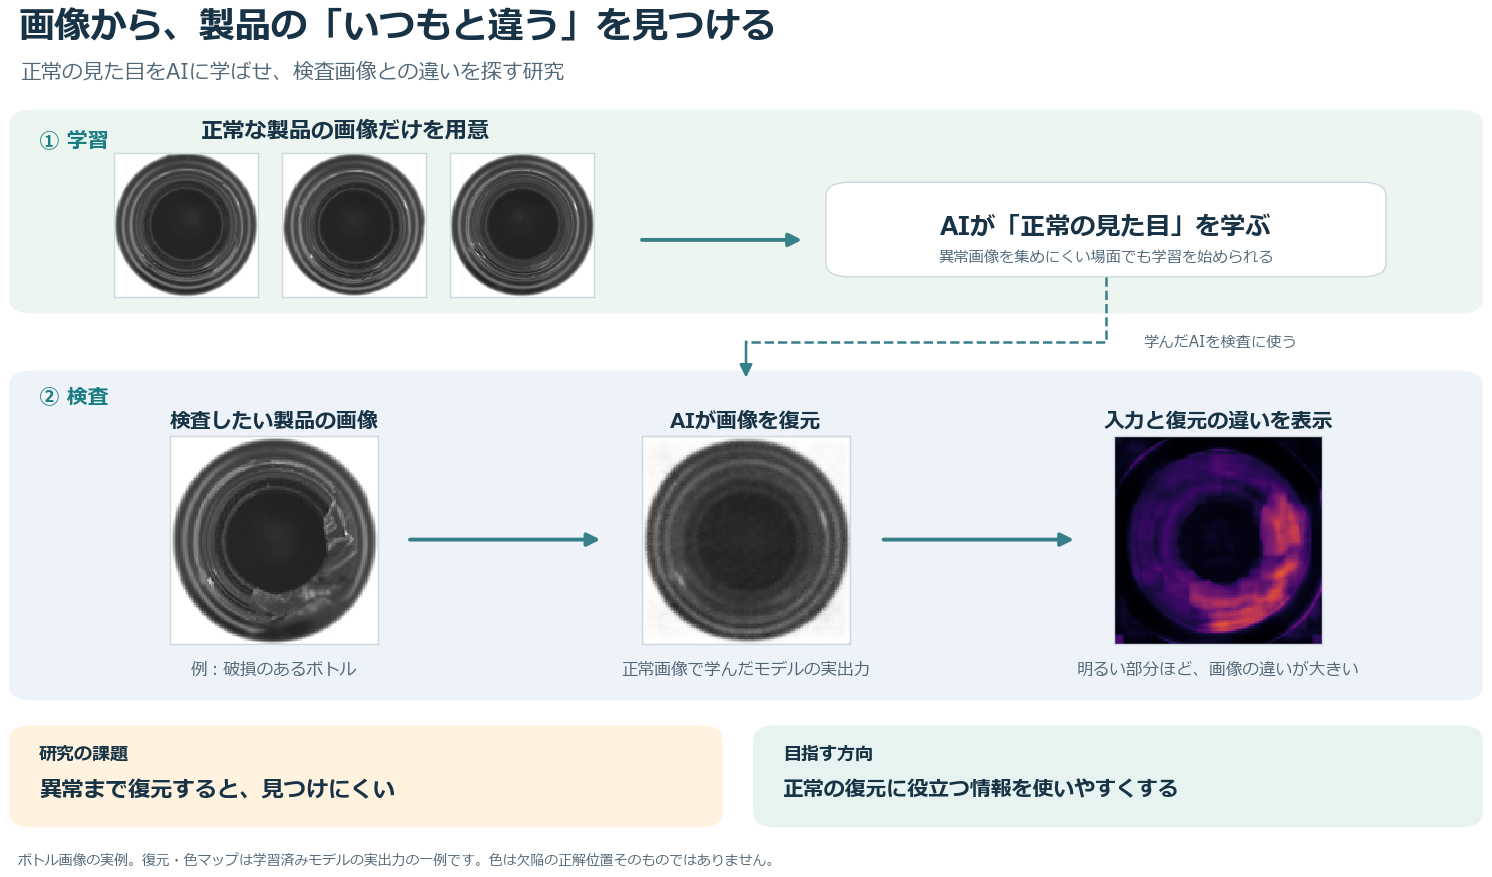

In [4]:
fig = plt.figure(figsize=(16, 9), facecolor='white')
label(fig, .045, .953, TITLE, 26, 'bold')
label(fig, .047, .903, SUBTITLE, 15, color=COLORS['muted'])

# 上段：学習。写真は正常な学習画像だけ。
rounded(fig, (.04, .635), .92, .225, COLORS['learning'])
label(fig, .058, .827, '① 学習', 15, 'bold', COLORS['accent'])
label(fig, .25, .838, '正常な製品の画像だけを用意', 16, 'bold', ha='center')
for x, image in zip([.105, .21, .315], train_pictures):
    picture(fig, [x, .652, .09, .16], image)
arrow(fig, (.435, .716), (.535, .716))
rounded(fig, (.55, .675), .35, .105, 'white', COLORS['line'])
label(fig, .725, .73, 'AIが「正常の見た目」を学ぶ', 18, 'bold', ha='center')
label(fig, .725, .697, '異常画像を集めにくい場面でも学習を始められる', 11, ha='center', color=COLORS['muted'])

# 学習済みAIが下段の復元を担当することを接続。
path = PlotPath([(.725, .675), (.725, .603), (.50, .603)],
                [PlotPath.MOVETO, PlotPath.LINETO, PlotPath.LINETO])
fig.add_artist(PathPatch(path, transform=fig.transFigure, fill=False,
                         color=COLORS['arrow'], linewidth=1.8, linestyle='--'))
arrow(fig, (.50, .603), (.50, .563), linewidth=1.8)
label(fig, .748, .603, '学んだAIを検査に使う', 11, color=COLORS['muted'])

# 下段：実際の検査画像→復元→誤差マップ。
rounded(fig, (.04, .205), .92, .365, COLORS['inspection'])
label(fig, .058, .542, '② 検査', 15, 'bold', COLORS['accent'])
for center, title in zip([.205, .50, .795],
                         ['検査したい製品の画像', 'AIが画像を復元', '入力と復元の違いを表示']):
    label(fig, center, .515, title, 15, 'bold', ha='center')
picture(fig, [.14, .267, .13, .2311], input_images[1])
picture(fig, [.435, .267, .13, .2311], restored[1])
picture(fig, [.73, .267, .13, .2311], error_maps[1], heat=True)
arrow(fig, (.29, .383), (.409, .383))
arrow(fig, (.586, .383), (.705, .383))
label(fig, .205, .239, '例：破損のあるボトル', 12, ha='center', color=COLORS['muted'])
label(fig, .50, .239, '正常画像で学んだモデルの実出力', 12, ha='center', color=COLORS['muted'])
label(fig, .795, .239, '明るい部分ほど、画像の違いが大きい', 12, ha='center', color=COLORS['muted'])

rounded(fig, (.04, .064), .445, .112, COLORS['challenge'])
rounded(fig, (.505, .064), .455, .112, COLORS['future'])
label(fig, .058, .146, '研究の課題', 13, 'bold')
label(fig, .058, .105, '異常まで復元すると、見つけにくい', 16, 'bold')
label(fig, .523, .146, '目指す方向', 13, 'bold')
label(fig, .523, .105, '正常の復元に役立つ情報を使いやすくする', 15, 'bold')
label(fig, .045, .027,
      'ボトル画像の実例。復元・色マップは学習済みモデルの実出力の一例です。色は欠陥の正解位置そのものではありません。',
      10, color=COLORS['muted'])
export_figure(fig, '研究概要_正常を学んで異常を探す')


## 4. 図②：正常と破損の実際の動作例

両行で同じモデル・前処理・平均推論を使います。正常画像でも、復元しきれない模様や輪郭に違いが出る場合があります。色だけで欠陥が確定するわけではありません。


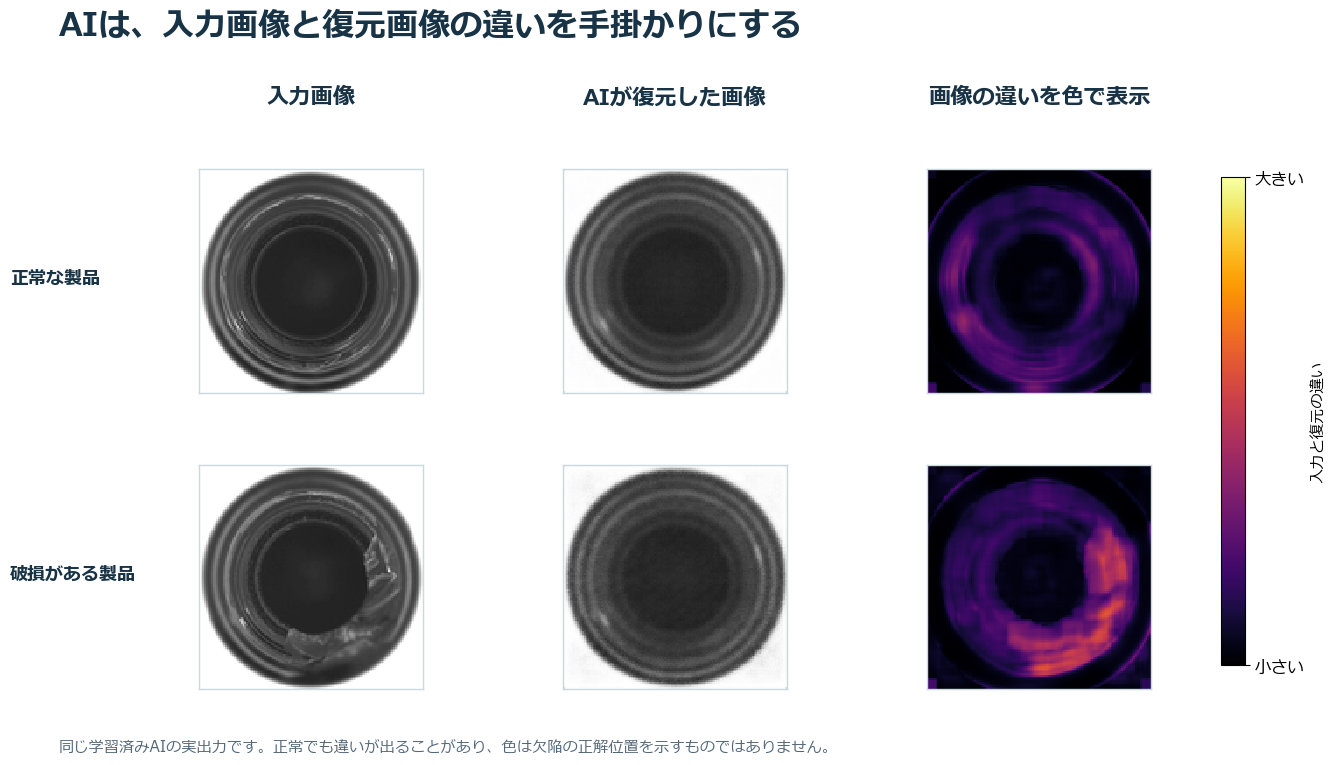

In [5]:
fig = plt.figure(figsize=(14, 8), facecolor='white')
label(fig, .06, .95, 'AIは、入力画像と復元画像の違いを手掛かりにする', 23, 'bold')
centers = [.24, .50, .76]
for center, title in zip(centers, ['入力画像', 'AIが復元した画像', '画像の違いを色で表示']):
    label(fig, center, .86, title, 16, 'bold', ha='center')
map_artist = None
for row, (name, y) in enumerate([('正常な製品', .49), ('破損がある製品', .12)]):
    label(fig, .025, y+.145, name, 13, 'bold', va='center')
    for col, center in enumerate(centers):
        image = input_images[row] if col == 0 else (restored[row] if col == 1 else error_maps[row])
        ax = picture(fig, [center-.08, y, .16, .28], image, heat=(col == 2))
        if col == 2: map_artist = ax.images[0]
cax = fig.add_axes([.89, .15, .017, .61])
bar = fig.colorbar(map_artist, cax=cax)
bar.set_ticks([MAP_MIN, MAP_MAX]); bar.set_ticklabels(['小さい', '大きい'])
bar.set_label('入力と復元の違い', fontsize=11)
label(fig, .06, .047,
      '同じ学習済みAIの実出力です。正常でも違いが出ることがあり、色は欠陥の正解位置を示すものではありません。',
      11, color=COLORS['muted'])
export_figure(fig, '動作例_正常と破損の入力復元比較')


## 5. 作成条件とファイルの確認（説明者用）

ここは見学者に見せる図の外に置く技術記録です。入力と重みの識別情報を残し、図を再現できるようにします。


In [6]:
assert all(file_hash(ROOT / relative) == digest for relative, digest in source_hashes.items())
figure_paths = sorted(EXPORT_DIR.glob('*.png')) + sorted(EXPORT_DIR.glob('*.svg'))
for path in figure_paths:
    print(path.relative_to(ROOT).as_posix())
record = {'model': MODEL_PATH.relative_to(ROOT).as_posix(), 'inference': 'posterior mean; model.eval(); sample=False',
          'train_examples': list(TRAIN_EXAMPLE_NAMES), 'test_examples': [NORMAL_EXAMPLE, ABNORMAL_EXAMPLE],
          'preprocessing': 'CenterCrop820 -> Resize128 LANCZOS -> Grayscale -> ToTensor',
          'error_map': '1 - SSIM; window=11; data_range=1.0', 'map_range': [MAP_MIN, MAP_MAX],
          'image_and_model_sha256': source_hashes, 'font': FONT,
          'exports': [path.relative_to(ROOT).as_posix() for path in figure_paths]}
print(json.dumps(record, ensure_ascii=False, indent=2))


docs/figures/lab_visit_20261023/動作例_正常と破損の入力復元比較.png
docs/figures/lab_visit_20261023/研究概要_正常を学んで異常を探す.png
docs/figures/lab_visit_20261023/動作例_正常と破損の入力復元比較.svg
docs/figures/lab_visit_20261023/研究概要_正常を学んで異常を探す.svg
{
  "model": "saved_models/rotation_control_20261021/20261021_232232_a54302ed/seed_42/A_original/model_final.pth",
  "inference": "posterior mean; model.eval(); sample=False",
  "train_examples": [
    "000.png",
    "001.png",
    "002.png"
  ],
  "test_examples": [
    "good/000.png",
    "broken_large/000.png"
  ],
  "preprocessing": "CenterCrop820 -> Resize128 LANCZOS -> Grayscale -> ToTensor",
  "error_map": "1 - SSIM; window=11; data_range=1.0",
  "map_range": [
    0.0,
    2.0
  ],
  "image_and_model_sha256": {
    "saved_models/rotation_control_20261021/20261021_232232_a54302ed/seed_42/A_original/model_final.pth": "e5e55ad93ec060bd11c541c140d6849d8d87aabfa77a540c81359be9b90b4995",
    "data/bottle/train/good/000.png": "8a25eb07475a5102f4823fefd82662dd65f8f2a0a333bf9581